In [88]:
import numpy as np
import matplotlib.pyplot as plt
import sys
from pathlib import Path
sys.path.append(str(Path().resolve().parent))
import cryocon

Tests 1: Check if it returns the correct values for a trivial case

Both should return True if the array doesnt vary and it is at the temperature setpoint

In [84]:
Sampling_time = 10  # seconds
Sampling_frequency = 0.1  # seconds
Temperature_setpoint = 1 # Kelvin
Maximum_offset = 0.1 # Kelvin
Maximum_std = 0.05 # Kelvin
temperature_array = np.ones(100)
Centinel_offset, Centinel_std, average_temperature, std = cryocon.Check_for_stable_temperature(Maximum_offset, Maximum_std, Temperature_setpoint, temperature_array, Sampling_time, Sampling_frequency)
Centinel_offset, Centinel_std, average_temperature, std

(np.True_, np.True_, np.float64(1.0), np.float64(0.0))

Should return false for the offset if it is stable but at a different temperature

In [3]:
temperature_array = np.zeros(100)
Centinel_offset, Centinel_std, average_temperature, std = cryocon.Check_for_stable_temperature(Maximum_offset, Maximum_std, Temperature_setpoint, temperature_array, Sampling_time, Sampling_frequency)
Centinel_offset, Centinel_std, average_temperature, std

(np.False_, np.True_, np.float64(0.0), np.float64(0.0))

Should return false for the std if it is not stable but return true for the average if it is at the setpoint

In [53]:
temperature_array = np.zeros(100)
for i in range(100):
    if i%2 ==0:
        temperature_array[i] = 2
Centinel_offset, Centinel_std, average_temperature, std = cryocon.Check_for_stable_temperature(Maximum_offset, Maximum_std, Temperature_setpoint, temperature_array, Sampling_time, Sampling_frequency)
Centinel_offset, Centinel_std, average_temperature, std

(np.True_,
 np.False_,
 np.float64(0.99500004166625),
 np.float64(0.999987500130207))

By varying the variance in the data one would expect to see either false or true for the std on most cases.

In [81]:
for i in range(100):
    temperature_array[i] = 1 + np.random.normal(0, 0.05)  
Centinel_offset, Centinel_std, average_temperature, std = cryocon.Check_for_stable_temperature(Maximum_offset, Maximum_std, Temperature_setpoint, temperature_array, Sampling_time, Sampling_frequency)
Centinel_offset, Centinel_std, average_temperature, std

(np.True_,
 np.True_,
 np.float64(1.0028819543359713),
 np.float64(0.03981763991761109))

Test 2: See if the exponential weight is working as expected

In [82]:
t1 = np.zeros(100)
t2 = np.ones(100)
temperature_array = np.concatenate((t1, t2))
Centinel_offset, Centinel_std, average_temperature, std = cryocon.Check_for_stable_temperature(Maximum_offset, Maximum_std, Temperature_setpoint, temperature_array, Sampling_time, Sampling_frequency)
Centinel_offset, Centinel_std, average_temperature, std

(np.False_,
 np.False_,
 np.float64(0.7310585786300048),
 np.float64(0.44340944198503696))

In [85]:
t1 = np.zeros(100)
t2 = np.ones(300)
temperature_array = np.concatenate((t1, t2))
Centinel_offset, Centinel_std, average_temperature, std = cryocon.Check_for_stable_temperature(Maximum_offset, Maximum_std, Temperature_setpoint, temperature_array, Sampling_time, Sampling_frequency)
Centinel_offset, Centinel_std, average_temperature, std

(np.True_,
 np.False_,
 np.float64(0.967941396719915),
 np.float64(0.17615575277525033))

In [86]:
t1 = np.zeros(300)
t2 = np.ones(300)
temperature_array = np.concatenate((t1, t2))
Centinel_offset, Centinel_std, average_temperature, std = cryocon.Check_for_stable_temperature(Maximum_offset, Maximum_std, Temperature_setpoint, temperature_array, Sampling_time, Sampling_frequency)
Centinel_offset, Centinel_std, average_temperature, std

(np.True_,
 np.False_,
 np.float64(0.9525741268224333),
 np.float64(0.21254801747114022))

In [87]:
t1 = np.zeros(600)
t2 = np.ones(600)
temperature_array = np.concatenate((t1, t2))
Centinel_offset, Centinel_std, average_temperature, std = cryocon.Check_for_stable_temperature(Maximum_offset, Maximum_std, Temperature_setpoint, temperature_array, Sampling_time, Sampling_frequency)
Centinel_offset, Centinel_std, average_temperature, std

(np.True_,
 np.True_,
 np.float64(0.9975273768433652),
 np.float64(0.049663963709716596))

Seems to be working as expected but would worth thinking about what is the best value for the weight parameter, at the moment it is (Sampling_time/sampling_frequency)^-1 so the last datapoint in the sampling time has a 1/e decrease 

Test 3: Simulate something more complicated and see how does it react

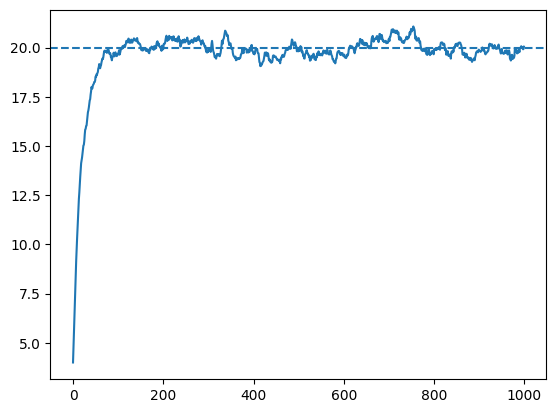

(np.False_,
 np.False_,
 np.float64(19.869147386490592),
 np.float64(0.2861232634935854))

In [94]:
N = 1000
temperature_array = np.zeros(N)

temperature_array[0] = 4.0          # Initial Temperature
Temperature_setpoint = 20.0        # Setpoint Temperature
alpha = 0.05        # Response velocity

for i in range(N-1):
    temperature_array[i+1] = temperature_array[i] + alpha * (Temperature_setpoint  - temperature_array[i])+ np.random.normal(0, 0.1) 

plt.plot(temperature_array)
plt.axhline(Temperature_setpoint, linestyle="--")
plt.show()
Centinel_offset, Centinel_std, average_temperature, std = cryocon.Check_for_stable_temperature(Maximum_offset, Maximum_std, Temperature_setpoint, temperature_array, Sampling_time, Sampling_frequency)
Centinel_offset, Centinel_std, average_temperature, std